# 04 · Shackleton: what Lantern needs from the map

**Milestone 4 of the Lunar Hazard Map.** Shackleton crater is Lantern's Profile 1, and it sits inside NASA's 5 m map, so everything here uses the sharp map directly. The notebook answers five questions the Lantern pages leave open:

1. **Is the crater the size we think?** We check the measured diameter and depth against published values.
2. **How steep must a rover climb?** We find the gentlest possible drive from the rim to the floor, and how much of the floor a scout can drive at each slope limit.
3. **Where does the tether go down the wall?** We find the cheapest route from the rim tower to the floor. It prefers shadow, because the cable only superconducts in the cold. We also report its true length.
4. **Where do the hubs go?** We place hubs by *driving* distance on the floor (Lantern's k-center rule), and measure the floor cable that joins them.
5. **Can the tower see the hubs?** We check line of sight for the laser backup, including the Moon's curvature.

It ends with a table comparing Lantern's placeholder numbers to what the map measures.

**Before running:** you need `ldem_87s_5mpp.tif` and `ldec_87s_5mpp.tif` (Milestone 1) and `LPSR_80S_20MPP_ADJ.TIF` (Milestone 2), all in `~/lunar/data/`. There's nothing new to download. It takes a few minutes, mostly the route search.

**Number labels.** *Sourced* = from a cited page or paper. *Placeholder* = a setting the team still has to confirm. *Measured* = computed here from NASA data.


**Data citations:** Barker et al. 2021, *Planet. Space Sci.* 203, 105119, doi:10.1016/j.pss.2020.105119 (5 m mosaic). Barker et al. 2023, *Planet. Sci. J.* 4, 183, doi:10.3847/PSJ/acf3e1 (permanent shadow map).

## Setup

In [13]:
import os, json, time, math
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import rasterio
from rasterio.windows import Window, from_bounds
from rasterio.warp import reproject, Resampling
from affine import Affine
from scipy import ndimage
from skimage.graph import MCP_Geometric

plt.rcParams.update({"figure.dpi": 110, "image.origin": "upper"})
pd.set_option("display.width", 160)

In [14]:
# ---------------- Settings ----------------
DATA = Path(os.environ.get("LUNAR_DATA", Path.home() / "lunar" / "data"))
FIG = Path("figures"); RESULTS = Path("results")
for d in (FIG, RESULTS):
    d.mkdir(parents=True, exist_ok=True)
F5 = {"elev": DATA / "ldem_87s_5mpp.tif", "count": DATA / "ldec_87s_5mpp.tif"}
F_PSR = DATA / "LPSR_80S_20MPP_ADJ.TIF"

MOON_R = 1_737_400.0                          # m, LOLA reference sphere
SHACK_LAT, SHACK_LON = -89.67, 129.78         # SOURCED: USGS Gazetteer of Planetary Nomenclature (as notebooks 01-02)
PUB_DIAMETER_KM, PUB_DEPTH_KM = 21.0, 4.2     # SOURCED: published Shackleton diameter and depth (see Sources)
CROP_KM = float(os.environ.get("LUNAR_CROP_KM", 30))   # window around the crater centre (setting)
GRID_M = 10                                   # analysis grid. Each 10 m cell takes the STEEPEST of its four 5 m
                                              # pixels, so anything that avoids a 10 m no-go cell also avoids 5 m no-go.

# Terrain classes (same as notebooks 01-03)
SAFE_MAX_DEG = 15.0     # SOURCED: NASA VIPER is rated for slopes up to 15 deg
NOGO_MIN_DEG = 25.0     # PLACEHOLDER: project plan

# Lantern settings
SCOUT_MAX_DEG = 15.0    # PLACEHOLDER: scouts assumed no better than VIPER's sourced 15 deg rating
RAPPEL_MAX_DEG = 45.0   # SOURCED: Michigan Tech T-REX tether rover descended a 45 deg slope (Lantern source 1)
SUNLIT_PENALTY = 3.0    # PLACEHOLDER: a metre of tether outside permanent shadow "costs" as much as 3 shadowed metres,
                        # because the cable only superconducts when cold
SLOPE_WEIGHT = 2.0      # setting: extra route cost for steepness (cost = 1 + 2 x (slope / 45)^2 per metre)
FLOOR_FRAC = 0.05       # PLACEHOLDER: "floor" = the lowest 5% of the crater's depth, joined to the lowest point
TOWER_XY = None         # None = PLACEHOLDER rule: the highest point on the rim crest. Or set (x, y) in metres.
TOWER_H_M = 50.0        # PLACEHOLDER: height of the laser on the Lighthouse tower
HUB_ANT_M = 2.0         # PLACEHOLDER: height of a hub's laser receiver
K_MAX = 6               # hub counts to try
K_SHOW = 4              # PLACEHOLDER: Lantern's default of 4 hubs, used for the map and line-of-sight check
SORTIE_R_M = 500.0      # PLACEHOLDER: Lantern says one scout sortie reaches "hundreds of metres"
LANTERN_WALL_KM = 1.8   # PLACEHOLDER in Lantern pages: "about 1.8 km of wall"
LANTERN_FLOOR_CABLE_KM = 2.2   # PLACEHOLDER in Lantern pages: "2.2 km of floor cable" for 4 hubs

missing = [p.name for p in [*F5.values(), F_PSR] if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing in {DATA}: {missing}. See download_m1.sh / download_m2.sh.")
print("Data folder:", DATA)

Data folder: /Users/razbinkarkidoli/lunar/data


In [15]:
# ---------------- Helpers ----------------
def latlon_to_xy(lat, lon):
    rho = 2 * MOON_R * np.tan(np.radians(90 + np.asarray(lat)) / 2)
    return rho * np.sin(np.radians(lon)), rho * np.cos(np.radians(lon))

def read_window(path, w):
    with rasterio.open(path) as s:
        a = s.read(1, window=w, masked=True)
    a = np.ma.filled(a.astype("float32"), np.nan)
    a[~np.isfinite(a) | (np.abs(a) > 1e30)] = np.nan
    return a

def slope_deg(dem, res):
    gy, gx = np.gradient(dem, res)
    return np.degrees(np.arctan(np.hypot(gx, gy))).astype("float32")

def hillshade(dem, res, az=45, alt=45):
    gy, gx = np.gradient(dem, res)
    sl = np.arctan(np.hypot(gx, gy)); asp = np.arctan2(-gy, -gx)
    a, z = np.radians(360 - az + 90), np.radians(90 - alt)
    return np.clip(np.cos(z) * np.cos(sl) + np.sin(z) * np.sin(sl) * np.cos(a - asp), 0, 1)

def block(a, k, f):
    n0, n1 = a.shape[0] // k, a.shape[1] // k
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return f(a[:n0 * k, :n1 * k].reshape(n0, k, n1, k), axis=(1, 3))

CLASS_CMAP = ListedColormap(["#2e9e5b", "#f0b429", "#d64545"])
def classify(s):
    c = np.full(s.shape, 255, np.uint8); ok = np.isfinite(s)
    c[ok & (s < SAFE_MAX_DEG)] = 0; c[ok & (s >= SAFE_MAX_DEG) & (s < NOGO_MIN_DEG)] = 1; c[ok & (s >= NOGO_MIN_DEG)] = 2
    return c

def km(v): return v / 1000.0

## A · Load Shackleton and check its shape

**Plain English.** We cut a square around the crater out of the 5 m map. Then we find the rim (the highest point along each of 360 directions from the centre) and the floor (the lowest part). We check the diameter and depth against published numbers. If they match, the map and our geometry are trustworthy.

In [16]:
t0 = time.time()
CX, CY = latlon_to_xy(SHACK_LAT, SHACK_LON)
half = CROP_KM * 1000 / 2
with rasterio.open(F5["elev"]) as s:
    w = from_bounds(CX - half, CY - half, CX + half, CY + half, transform=s.transform)
    w = Window(int(round(w.col_off)), int(round(w.row_off)), int(round(w.width)) // 2 * 2, int(round(w.height)) // 2 * 2)
    t5, CRS5 = s.window_transform(w), s.crs
    assert abs(s.transform.a - 5) < 1e-6
e5 = read_window(F5["elev"], w)
c5 = read_window(F5["count"], w)
s5 = slope_deg(e5, 5)
print(f"5 m window: {e5.shape[1]} x {e5.shape[0]} px ({CROP_KM:.0f} km square), read in {time.time() - t0:.0f} s, "
      f"no-data share {np.isnan(e5).mean():.2%}")

# 10 m analysis grid
K = GRID_M // 5
e10 = block(e5, K, np.nanmean).astype("float32")
s10 = block(s5, K, np.nanmax).astype("float32")             # steepest 5 m pixel in each 10 m cell
real10 = block((np.nan_to_num(c5) > 0).astype("float32"), K, np.mean)
t10 = t5 * Affine.scale(K)
valid10 = np.isfinite(e10) & np.isfinite(s10)

# Permanent shadow map (20 m) onto the 10 m grid
with rasterio.open(F_PSR) as s:
    b = rasterio.transform.array_bounds(e10.shape[0], e10.shape[1], t10)
    wp = from_bounds(b[0] - 100, b[1] - 100, b[2] + 100, b[3] + 100, transform=s.transform).round_offsets().round_lengths()
    psr_src = s.read(1, window=wp, masked=True).filled(0).astype("float32"); tp = s.window_transform(wp)
psr10 = np.zeros(e10.shape, "float32")
reproject(psr_src, psr10, src_transform=tp, src_crs=CRS5, dst_transform=t10, dst_crs=CRS5, resampling=Resampling.nearest)
psr10 = psr10 > 0

# Coordinates of 10 m cell centres, distance from crater centre
rows, cols = np.indices(e10.shape)
X10 = t10.c + (cols + 0.5) * t10.a
Y10 = t10.f + (rows + 0.5) * t10.e
R10 = np.hypot(X10 - CX, Y10 - CY)
def rc_of(x, y):
    return int((y - t10.f) / t10.e), int((x - t10.c) / t10.a)
def xy_of(r, c):
    return t10.c + (c + 0.5) * t10.a, t10.f + (r + 0.5) * t10.e

# Rim crest: highest point along 360 rays from the centre, between 4 km and the window edge
radii = np.arange(4000, half - 200, GRID_M)
az = np.radians(np.arange(360))
RX = CX + np.outer(np.sin(az), radii); RY = CY + np.outer(np.cos(az), radii)
rr_ = ((RY - t10.f) / t10.e).astype(int); cc_ = ((RX - t10.c) / t10.a).astype(int)
prof = np.where(np.isfinite(e10[rr_, cc_]), e10[rr_, cc_], -np.inf)
k = prof.argmax(axis=1)
rim_r, rim_z = radii[k], prof[np.arange(360), k]
rim_rc = np.stack([rr_[np.arange(360), k], cc_[np.arange(360), k]], 1)
RIM_R = float(np.median(rim_r)); RIM_Z = float(np.median(rim_z))

# Floor: lowest part of the bowl, joined to the lowest point
inner = valid10 & (R10 < 0.6 * RIM_R)
z_floor = float(np.nanpercentile(e10[inner], 0.5))
DEPTH = RIM_Z - z_floor
lab, _ = ndimage.label(valid10 & (R10 < RIM_R) & (e10 < z_floor + FLOOR_FRAC * DEPTH))
low = np.unravel_index(np.where(inner, e10, np.inf).argmin(), e10.shape)
floor = lab == lab[low] if lab[low] > 0 else np.zeros_like(valid10)
floor_area = floor.sum() * GRID_M ** 2
wall = valid10 & (R10 < RIM_R) & ~floor & ~ndimage.binary_dilation(floor, iterations=3)

# Tower site
if TOWER_XY is None:
    i = int(np.argmax(rim_z)); TOWER_RC = tuple(rim_rc[i]); TOWER_RULE = "placeholder: highest point on the rim crest"
else:
    TOWER_RC = rc_of(*TOWER_XY); TOWER_RULE = "set by the team"
tower_xy = xy_of(*TOWER_RC)

geo = pd.DataFrame([
    dict(item="Rim diameter (km)", measured=2 * km(RIM_R), published=PUB_DIAMETER_KM, note="median over 360 directions"),
    dict(item="Depth, rim to floor (km)", measured=km(DEPTH), published=PUB_DEPTH_KM, note="median rim height minus floor"),
    dict(item="Floor, equal-area diameter (km)", measured=2 * km(math.sqrt(floor_area / math.pi)), published=np.nan,
         note=f"lowest {FLOOR_FRAC:.0%} of depth (placeholder)"),
    dict(item="Median wall slope, 5 m (deg)", measured=float(np.nanmedian(s5[np.repeat(np.repeat(wall, K, 0), K, 1)[:s5.shape[0], :s5.shape[1]]])),
         published=np.nan, note="between floor and rim"),
    dict(item="Floor in permanent shadow (%)", measured=100 * psr10[floor].mean(), published=np.nan, note="NASA PSR map"),
    dict(item="Floor pixels with a real laser shot (%)", measured=100 * float(real10[floor].mean()), published=np.nan,
         note="rest is filled in"),
])
print("Shackleton geometry (measured vs SOURCED published values):")
display(geo.round(2))
print(f"Tower site ({TOWER_RULE}): x {km(tower_xy[0]):.2f} km, y {km(tower_xy[1]):.2f} km, "
      f"elevation {e10[TOWER_RC]:.0f} m, in permanent shadow: {bool(psr10[TOWER_RC])}")

5 m window: 6000 x 6000 px (30 km square), read in 1 s, no-data share 0.00%
Shackleton geometry (measured vs SOURCED published values):


,item,measured,published,note
0,Rim diameter (km),20.74,21.0,median over 360 directions
1,"Depth, rim to floor (km)",4.07,4.2,median rim height minus floor
2,"Floor, equal-area diameter (km)",6.09,NaN,lowest 5% of depth (placeholder)
3,"Median wall slope, 5 m (deg)",29.88,NaN,between floor and rim
4,Floor in permanent shadow (%),100.00,NaN,NASA PSR map
5,Floor pixels with a real laser shot (%),10.51,NaN,rest is filled in


Tower site (placeholder: highest point on the rim crest): x -2.81 km, y -6.04 km, elevation 1736 m, in permanent shadow: False


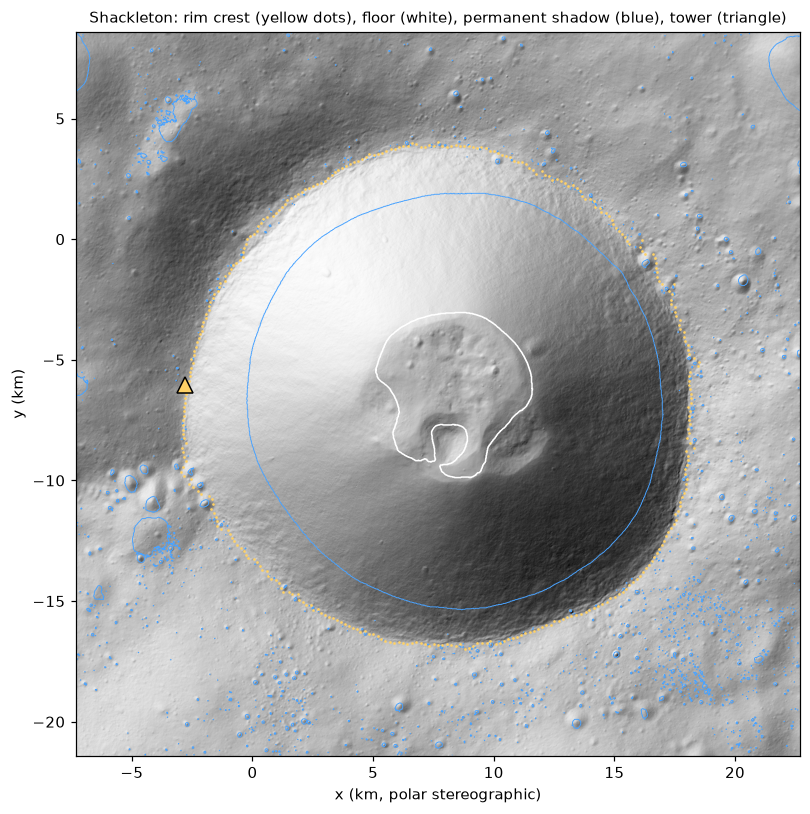

In [17]:
step = 2
ext10 = [km(t10.c), km(t10.c + t10.a * e10.shape[1]), km(t10.f + t10.e * e10.shape[0]), km(t10.f)]
hs = hillshade(e10[::step, ::step], GRID_M * step)
def base_map(ax, title):
    ax.imshow(hs, cmap="gray", extent=ext10)
    ax.contour(X10[::step, ::step] / 1e3, Y10[::step, ::step] / 1e3, psr10[::step, ::step].astype(float), levels=[0.5],
               colors="#4aa3ff", linewidths=0.6)
    ax.plot(*(np.array([xy_of(*rc) for rc in rim_rc]).T / 1e3), ".", ms=1.5, color="#ffd166")
    ax.contour(X10[::step, ::step] / 1e3, Y10[::step, ::step] / 1e3, floor[::step, ::step].astype(float), levels=[0.5],
               colors="white", linewidths=1)
    ax.plot(km(tower_xy[0]), km(tower_xy[1]), "^", ms=11, color="#ffd166", mec="k")
    ax.set_title(title, fontsize=10); ax.set_xlabel("x (km, polar stereographic)"); ax.set_ylabel("y (km)")
fig, ax = plt.subplots(figsize=(7.5, 7.5))
base_map(ax, "Shackleton: rim crest (yellow dots), floor (white), permanent shadow (blue), tower (triangle)")
plt.tight_layout(); plt.savefig(FIG / "M4_shackleton_geometry.png", dpi=150); plt.show()

## B · The hazard map

The safe / caution / no-go classes from the 5 m slope, shown on the 10 m grid (each cell takes its steepest 5 m pixel, so this map is slightly cautious).

Hazard classes from 5 m slope (measured):


,zone,area_km2,safe %,caution %,no-go %
0,floor,29.1,87.2,11.9,0.9
1,wall,308.0,6.8,13.3,79.9
2,rim zone (rim to rim + 2 km),142.9,49.0,46.7,4.3


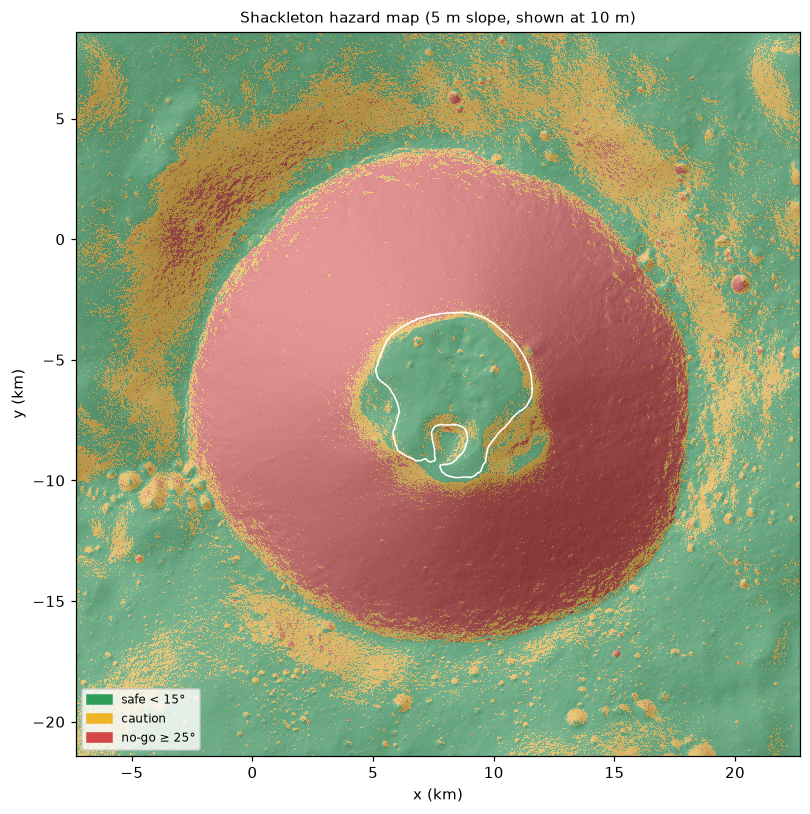

In [18]:
cls10 = classify(s10)
zones = {"floor": floor, "wall": wall, "rim zone (rim to rim + 2 km)": valid10 & (R10 >= RIM_R) & (R10 < RIM_R + 2000)}
cls5 = classify(s5)
def up(m): return np.repeat(np.repeat(m, K, 0), K, 1)[:cls5.shape[0], :cls5.shape[1]]
rowsB = []
for name, m in zones.items():
    c = cls5[up(m)]; c = c[c != 255]
    rowsB.append(dict(zone=name, area_km2=m.sum() * GRID_M ** 2 / 1e6,
                      **{f"{n} %": 100 * (c == i).mean() for i, n in enumerate(["safe", "caution", "no-go"])}))
B = pd.DataFrame(rowsB)
print("Hazard classes from 5 m slope (measured):"); display(B.round(1))

fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.imshow(hs, cmap="gray", extent=ext10)
ax.imshow(np.ma.masked_equal(cls10[::step, ::step], 255), cmap=CLASS_CMAP, vmin=-0.5, vmax=2.5, alpha=0.55,
          extent=ext10, interpolation="nearest")
ax.contour(X10[::step, ::step] / 1e3, Y10[::step, ::step] / 1e3, floor[::step, ::step].astype(float), levels=[0.5], colors="white", linewidths=1)
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(["#2e9e5b", "#f0b429", "#d64545"],
          [f"safe < {SAFE_MAX_DEG:.0f}°", "caution", f"no-go ≥ {NOGO_MIN_DEG:.0f}°"])], loc="lower left", fontsize=8)
ax.set_title("Shackleton hazard map (5 m slope, shown at 10 m)", fontsize=10)
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)")
plt.tight_layout(); plt.savefig(FIG / "M4_hazard_map.png", dpi=150); plt.show()

## C · How steep must a rover climb?

**Plain English.** Two numbers set the rover's design:

- **Drive-down slope:** the gentlest possible drive from the rim to the floor. Every path down has a steepest spot. This finds the path whose steepest spot is as gentle as possible. A rover rated below this number *cannot* drive into the crater, so something has to carry it or lower it. (That is Lantern's rappelling tether rover.)
- **Floor reach:** at each slope limit, how much of the floor a scout can drive on, and how much of that is one connected piece it can roam without help.

Gentlest drive from the TOWER to the floor needs a rover rated for 31.6 deg (measured).
Gentlest drive from ANYWHERE on the rim crest needs 31.6 deg (measured).

Floor reach by rover slope limit (measured):


,slope_limit_deg,floor_drivable_pct,largest_connected_floor_pct,can_drive_rim_to_floor
0,10,63.2,61.8,False
1,15,84.7,84.0,False
2,20,94.2,94.0,False
3,25,98.5,98.5,False
4,30,99.9,99.9,False
5,35,100.0,100.0,True
6,40,100.0,100.0,True
7,45,100.0,100.0,True


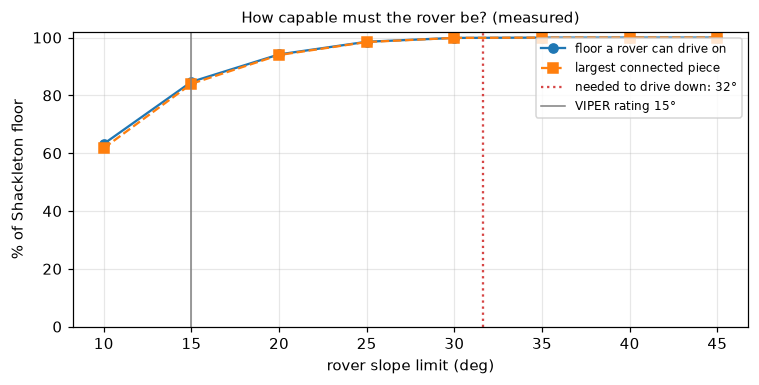

In [19]:
ok = valid10
rim_mask = np.zeros_like(ok); rim_mask[rim_rc[:, 0], rim_rc[:, 1]] = True
def connected(limit, src_mask):
    lab, _ = ndimage.label(ok & (s10 < limit), structure=np.ones((3, 3)))
    ids = np.unique(lab[src_mask & (lab > 0)])
    return np.isin(lab, ids[ids > 0])
def bottleneck(src_mask, lo=0.0, hi=90.0):
    if not connected(hi, src_mask)[floor].any():
        return np.nan
    while hi - lo > 0.25:
        mid = (lo + hi) / 2
        if connected(mid, src_mask)[floor].any(): hi = mid
        else: lo = mid
    return hi
tower_mask = np.zeros_like(ok); tower_mask[TOWER_RC] = True
DRIVE_DOWN_TOWER = bottleneck(tower_mask)
DRIVE_DOWN_ANY = bottleneck(rim_mask)
print(f"Gentlest drive from the TOWER to the floor needs a rover rated for {DRIVE_DOWN_TOWER:.1f} deg (measured).")
print(f"Gentlest drive from ANYWHERE on the rim crest needs {DRIVE_DOWN_ANY:.1f} deg (measured).")

limits = [10, 15, 20, 25, 30, 35, 40, 45]
rowsC = []
for L in limits:
    drv = floor & ok & (s10 < L)
    lab, n = ndimage.label(drv, structure=np.ones((3, 3)))
    biggest = np.bincount(lab.ravel())[1:].max() if n else 0
    rowsC.append(dict(slope_limit_deg=L, floor_drivable_pct=100 * drv.sum() / floor.sum(),
                      largest_connected_floor_pct=100 * biggest / floor.sum(),
                      can_drive_rim_to_floor=bool(np.isfinite(DRIVE_DOWN_ANY) and L >= DRIVE_DOWN_ANY)))
C = pd.DataFrame(rowsC)
print("\nFloor reach by rover slope limit (measured):"); display(C.round(1))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(C.slope_limit_deg, C.floor_drivable_pct, "o-", label="floor a rover can drive on")
ax.plot(C.slope_limit_deg, C.largest_connected_floor_pct, "s--", label="largest connected piece")
if np.isfinite(DRIVE_DOWN_ANY):
    ax.axvline(DRIVE_DOWN_ANY, color="#d64545", ls=":", label=f"needed to drive down: {DRIVE_DOWN_ANY:.0f}°")
ax.axvline(SAFE_MAX_DEG, color="gray", lw=1, label="VIPER rating 15°")
ax.set_xlabel("rover slope limit (deg)"); ax.set_ylabel("% of Shackleton floor"); ax.set_ylim(0, 102)
ax.set_title("How capable must the rover be? (measured)", fontsize=10); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "M4_rover_requirement.png", dpi=150); plt.show()

## D · The tether route down the wall

**Plain English.** The tether rover starts at the tower and rappels down to the floor. The search looks for the cheapest path, where:

- each metre costs more the steeper it is,
- a metre outside permanent shadow costs 3× more (placeholder), because the cable only superconducts in the cold,
- anything steeper than 45° is off limits (the slope the T-REX tether rover has been tested on).

For comparison, it also finds the route with no preference for shadow. Lengths are true 3D lengths along the ground, not map distance.

  route search (sunlit penalty 3.0) took 2 s
  route search (sunlit penalty 1.0) took 2 s
Tether routes, tower to floor (measured):


,route,length_3d_km,map_length_km,wall_part_3d_km,drop_m,in_shadow_pct,steepest_5m_deg,mean_slope_deg
0,prefers shadow (x3),9.36,8.18,9.36,4361.15,68.62,41.24,28.18
1,no shadow preference,9.30,8.13,9.30,4361.15,66.73,41.51,28.25


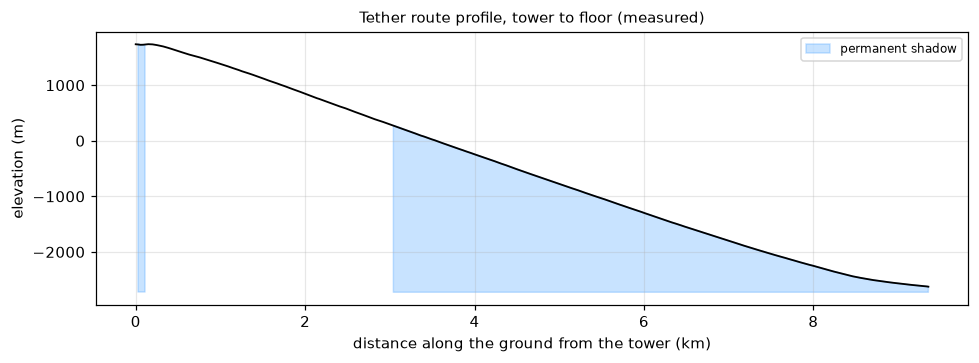

In [20]:
def tether_cost(sun_penalty):
    c = (1 + SLOPE_WEIGHT * (s10 / RAPPEL_MAX_DEG) ** 2) * np.where(psr10, 1.0, sun_penalty)
    return np.where(ok & (s10 <= RAPPEL_MAX_DEG), c, np.inf).astype("float64")

def plan(sun_penalty):
    t0 = time.time()
    m = MCP_Geometric(tether_cost(sun_penalty))
    cum, _ = m.find_costs([TOWER_RC])
    tgt = np.where(floor & np.isfinite(cum), cum, np.inf)
    if not np.isfinite(tgt).any():
        return None
    end = np.unravel_index(tgt.argmin(), tgt.shape)
    path = np.array(m.traceback(end))
    print(f"  route search (sunlit penalty {sun_penalty}) took {time.time() - t0:.0f} s")
    return path

def route_stats(path, name):
    r, c = path[:, 0], path[:, 1]
    dxy = np.hypot(np.diff(r), np.diff(c)) * GRID_M
    dz = np.diff(e10[r, c].astype("float64"))
    seg3d = np.hypot(dxy, np.nan_to_num(dz))
    on_floor = floor[r, c]
    first_floor = int(np.argmax(on_floor)) if on_floor.any() else len(r) - 1
    shadow = psr10[r, c][1:]
    return dict(route=name, length_3d_km=km(seg3d.sum()), map_length_km=km(dxy.sum()),
                wall_part_3d_km=km(seg3d[:first_floor].sum()), drop_m=float(e10[r[0], c[0]] - e10[r[-1], c[-1]]),
                in_shadow_pct=100 * float((seg3d * shadow).sum() / seg3d.sum()),
                steepest_5m_deg=float(s10[r, c].max()), mean_slope_deg=float(np.degrees(np.arctan(
                    np.abs(dz).sum() / max(dxy.sum(), 1)))))

route = plan(SUNLIT_PENALTY)
route_plain = plan(1.0)
if route is None:
    raise RuntimeError("No route from the tower to the floor under the 45 deg limit. Try another TOWER_XY.")
D = pd.DataFrame([route_stats(route, f"prefers shadow (x{SUNLIT_PENALTY:g})"),
                  route_stats(route_plain, "no shadow preference")])
print("Tether routes, tower to floor (measured):"); display(D.round(2))
HUB1 = tuple(route[-1])

# Profile
r, c = route[:, 0], route[:, 1]
dist = np.concatenate([[0], np.cumsum(np.hypot(np.hypot(np.diff(r), np.diff(c)) * GRID_M, np.diff(e10[r, c])))]) / 1e3
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(dist, e10[r, c], color="k", lw=1.2)
ax.fill_between(dist, e10[r, c].min() - 100, e10[r, c], where=psr10[r, c], color="#4aa3ff", alpha=0.3, step="mid",
                label="permanent shadow")
ax.set_xlabel("distance along the ground from the tower (km)"); ax.set_ylabel("elevation (m)")
ax.set_title("Tether route profile, tower to floor (measured)", fontsize=10); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "M4_tether_profile.png", dpi=150); plt.show()

## E · Where the hubs go

**Plain English.** The first hub sits where the tether reaches the floor. Each next hub goes to the floor spot that is the *longest drive* from every existing hub: the farthest-point rule Lantern's architecture page uses (Gonzalez 1985, a proven 2-approximation for k-center). Distances are driving distances on floor a scout can drive (under the scout slope limit), not straight lines. The hubs are then joined with the shortest cable network (a minimum spanning tree), following drivable paths.

The table answers Lantern's hub-count trade with real terrain: how far is the worst spot from a hub, how much of the floor is within one sortie of a hub, and how much cable that costs.

Tether reaches the floor at its edge; hub 1 sits 0 m away on the main drivable floor (measured).
Drivable floor (< 15 deg, placeholder): 84.7% of the floor; 99.2% of that connects to hub 1 by driving (measured). The rest needs the hopper, a rappel, or a higher slope limit.
Hub sweep (measured; sortie radius 500 m is a placeholder):


,hubs,worst_drive_to_hub_km,mean_drive_to_hub_km,floor_within_sortie_pct,floor_cable_km,total_tether_km
0,1,7.47,3.79,1.16,0.00,9.36
1,2,6.15,3.15,2.41,7.47,16.82
2,3,4.54,2.17,3.39,12.41,21.77
3,4,3.67,1.98,4.10,16.95,26.31
4,5,3.60,1.71,5.45,18.16,27.52
5,6,2.97,1.47,5.68,19.08,28.44


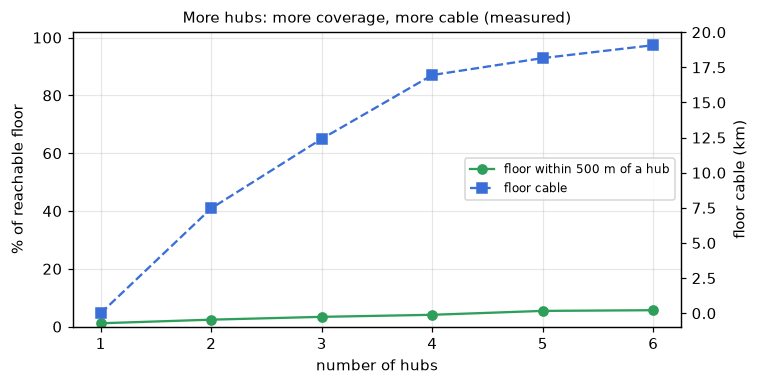

In [21]:
drv_floor = floor & ok & (s10 < SCOUT_MAX_DEG)
if not drv_floor.any():
    raise RuntimeError(f"No floor is drivable under {SCOUT_MAX_DEG} deg; raise SCOUT_MAX_DEG to place hubs.")
# Hub 1 goes on the MAIN drivable floor (the biggest connected piece), as close as possible to where the tether lands.
lab_f, n_f = ndimage.label(drv_floor, structure=np.ones((3, 3)))
main_floor = lab_f == (np.bincount(lab_f.ravel())[1:].argmax() + 1)
TETHER_END = HUB1
dd = ndimage.distance_transform_edt(~main_floor, return_indices=True)[1]
HUB1 = (int(dd[0][TETHER_END]), int(dd[1][TETHER_END]))
FLOOR_LINK_M = math.hypot(HUB1[0] - TETHER_END[0], HUB1[1] - TETHER_END[1]) * GRID_M
print(f"Tether reaches the floor at its edge; hub 1 sits {FLOOR_LINK_M:.0f} m away on the main drivable floor (measured).")
rs, cs = np.nonzero(floor); r0, r1, c0, c1 = rs.min() - 2, rs.max() + 3, cs.min() - 2, cs.max() + 3
sub = drv_floor[r0:r1, c0:c1]
mcp_floor = MCP_Geometric(np.where(sub, 1.0, np.inf))
def drive_from(rc):
    d, _ = mcp_floor.find_costs([(rc[0] - r0, rc[1] - c0)])
    return d * GRID_M

hubs = [HUB1]; dists = [drive_from(HUB1)]
reach = np.isfinite(dists[0])
nearest = dists[0].copy()
for _ in range(K_MAX - 1):
    nxt = np.unravel_index(np.where(reach, nearest, -1).argmax(), nearest.shape)
    hubs.append((nxt[0] + r0, nxt[1] + c0)); dists.append(drive_from(hubs[-1]))
    nearest = np.minimum(nearest, dists[-1])

def mst_length(n):
    Dm = np.array([[dists[i][hubs[j][0] - r0, hubs[j][1] - c0] for j in range(n)] for i in range(n)])
    Dm = np.minimum(Dm, Dm.T)
    inT = [0]; total = 0.0
    while len(inT) < n:
        best = min(((Dm[i, j], j) for i in inT for j in range(n) if j not in inT), key=lambda t: t[0])
        total += best[0]; inT.append(best[1])
    return total

wall_km = float(D.iloc[0].length_3d_km) + km(FLOOR_LINK_M)   # wall route + short link to hub 1
rowsE = []
for k in range(1, K_MAX + 1):
    nk = np.min(np.stack(dists[:k]), axis=0)[reach]
    rowsE.append(dict(hubs=k, worst_drive_to_hub_km=km(nk.max()), mean_drive_to_hub_km=km(nk.mean()),
                      floor_within_sortie_pct=100 * (nk <= SORTIE_R_M).mean(),
                      floor_cable_km=km(mst_length(k)), total_tether_km=wall_km + km(mst_length(k))))
E = pd.DataFrame(rowsE)
print(f"Drivable floor (< {SCOUT_MAX_DEG:.0f} deg, placeholder): {100 * drv_floor.sum() / floor.sum():.1f}% of the floor; "
      f"{100 * reach.sum() / max(sub.sum(), 1):.1f}% of that connects to hub 1 by driving (measured). "
      f"The rest needs the hopper, a rappel, or a higher slope limit.")
print(f"Hub sweep (measured; sortie radius {SORTIE_R_M:.0f} m is a placeholder):"); display(E.round(2))

fig, ax1 = plt.subplots(figsize=(7, 3.6))
ax1.plot(E.hubs, E.floor_within_sortie_pct, "o-", color="#2e9e5b", label=f"floor within {SORTIE_R_M:.0f} m of a hub")
ax1.set_ylabel("% of reachable floor"); ax1.set_xlabel("number of hubs"); ax1.set_ylim(0, 102)
ax2 = ax1.twinx(); ax2.plot(E.hubs, E.floor_cable_km, "s--", color="#3b6fd8", label="floor cable")
ax2.set_ylabel("floor cable (km)")
ax1.legend(handles=ax1.get_lines() + ax2.get_lines(), fontsize=8, loc="center right")
ax1.set_title("More hubs: more coverage, more cable (measured)", fontsize=10); ax1.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "M4_hub_sweep.png", dpi=150); plt.show()

## F · Can the tower see the hubs?

**Plain English.** Lantern's backup power is a laser from the tower to a hub, so the tower must be able to *see* the hub. We draw a straight line from the laser (placeholder 50 m up the tower) to each hub's receiver (placeholder 2 m up). If the ground pokes above that line anywhere, the hub is hidden. The Moon's curve is included: across 10 km the ground bulges about 7 m above a straight line.

We also check 1,500 random floor points, to see how much of the floor the tower can see at all.

In [22]:
def visible(rc_from, h_from, rc_to, h_to, step_m=5.0):
    x0, y0 = xy_of(*rc_from); x1, y1 = xy_of(*rc_to)
    Dd = math.hypot(x1 - x0, y1 - y0); n = max(int(Dd / step_m), 2)
    f = np.linspace(0, 1, n)[2:-2]
    xs, ys = x0 + f * (x1 - x0), y0 + f * (y1 - y0)
    rr = (ys - t10.f) / t10.e - 0.5; cc = (xs - t10.c) / t10.a - 0.5
    ground = ndimage.map_coordinates(np.nan_to_num(e10, nan=-1e9), [rr, cc], order=1, mode="nearest")
    z0 = e10[rc_from] + h_from; z1 = e10[rc_to] + h_to
    line = z0 + f * (z1 - z0) - (f * Dd) * ((1 - f) * Dd) / (2 * MOON_R)   # straight line sags below a curved surface
    return bool(np.all(line > ground)), float((line - ground).min())

rowsF = []
for i, h in enumerate(hubs[:K_SHOW]):
    vis, clearance = visible(TOWER_RC, TOWER_H_M, h, HUB_ANT_M)
    x, y = xy_of(*h)
    rowsF.append(dict(hub=i + 1, x_km=km(x), y_km=km(y), straight_line_km=km(math.hypot(x - tower_xy[0], y - tower_xy[1])),
                      in_shadow=bool(psr10[h]), tower_can_see=vis, min_clearance_m=clearance))
F = pd.DataFrame(rowsF)
print(f"Line of sight, tower ({TOWER_H_M:.0f} m) to hubs ({HUB_ANT_M:.0f} m) (measured; heights are placeholders):")
display(F.round(2))

fr, fc = np.nonzero(floor)
pick = np.random.default_rng(23).choice(len(fr), size=min(1500, len(fr)), replace=False)   # random sample of floor
seen = np.array([visible(TOWER_RC, TOWER_H_M, (fr[i], fc[i]), HUB_ANT_M)[0] for i in pick])
FLOOR_SEEN = 100 * seen.mean()
print(f"Share of the floor the tower can see: {FLOOR_SEEN:.0f}% ({len(pick):,} sample points, measured)")

Line of sight, tower (50 m) to hubs (2 m) (measured; heights are placeholders):


,hub,x_km,y_km,straight_line_km,in_shadow,tower_can_see,min_clearance_m
0,1,5.18,-5.70,8.00,True,False,-96.08
1,2,8.10,-9.80,11.55,True,False,-29.99
2,3,10.88,-4.81,13.76,True,False,-10.91
3,4,7.52,-9.20,10.81,True,False,-37.01


Share of the floor the tower can see: 0% (1,500 sample points, measured)


## G · The Profile 1 map

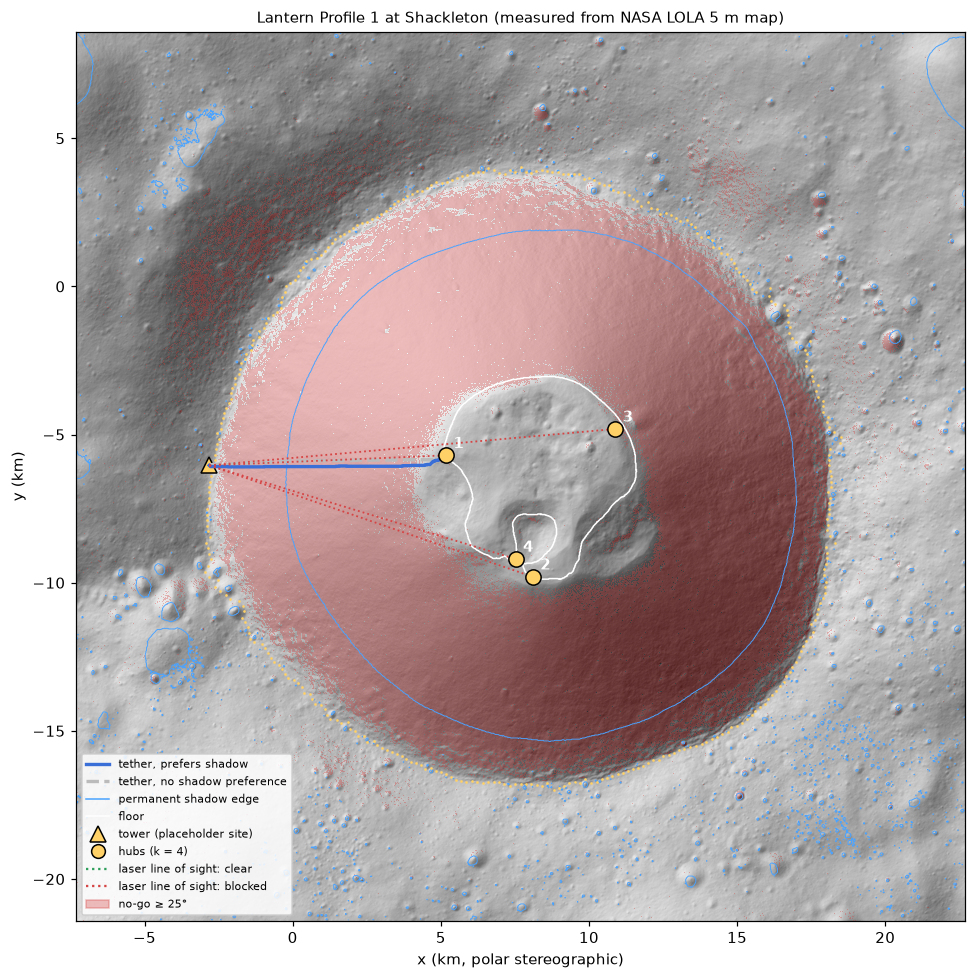

In [23]:
fig, ax = plt.subplots(figsize=(9, 9))
base_map(ax, "Lantern Profile 1 at Shackleton (measured from NASA LOLA 5 m map)")
ax.imshow(np.ma.masked_where(~(cls10[::step, ::step] == 2), cls10[::step, ::step]), cmap=ListedColormap(["#d64545"]),
          alpha=0.35, extent=ext10, interpolation="nearest")
for path, col, ls in ((route_plain, "#bbbbbb", "--"), (route, "#3b6fd8", "-")):
    xs, ys = zip(*[xy_of(r_, c_) for r_, c_ in path])
    ax.plot(np.array(xs) / 1e3, np.array(ys) / 1e3, ls, color=col, lw=2.2)
for i, h in enumerate(hubs[:K_SHOW]):
    x, y = xy_of(*h)
    vis = F.loc[i, "tower_can_see"]
    ax.plot([km(tower_xy[0]), km(x)], [km(tower_xy[1]), km(y)], ":", color="#2e9e5b" if vis else "#d64545", lw=1.2)
    ax.plot(km(x), km(y), "o", ms=10, color="#ffd166", mec="k"); ax.text(km(x) + 0.25, km(y) + 0.25, str(i + 1), color="w", fontsize=10, weight="bold")
ax.legend(handles=[Line2D([], [], color="#3b6fd8", lw=2.2, label="tether, prefers shadow"),
                   Line2D([], [], color="#bbbbbb", lw=2.2, ls="--", label="tether, no shadow preference"),
                   Line2D([], [], color="#4aa3ff", lw=1, label="permanent shadow edge"),
                   Line2D([], [], color="white", lw=1, label="floor"),
                   Line2D([], [], marker="^", ls="", color="#ffd166", mec="k", ms=10, label="tower (placeholder site)"),
                   Line2D([], [], marker="o", ls="", color="#ffd166", mec="k", ms=9, label=f"hubs (k = {K_SHOW})"),
                   Line2D([], [], color="#2e9e5b", ls=":", label="laser line of sight: clear"),
                   Line2D([], [], color="#d64545", ls=":", label="laser line of sight: blocked"),
                   Patch(color="#d64545", alpha=0.35, label=f"no-go ≥ {NOGO_MIN_DEG:.0f}°")],
          loc="lower left", fontsize=7.5, framealpha=0.85)
plt.tight_layout(); plt.savefig(FIG / "M4_profile1_map.png", dpi=170); plt.show()

## H · Lantern's numbers vs the map

Placeholders from the Lantern pages, next to what the map measures. Where they disagree a lot, the Lantern pages and simulator should be updated before the proposal.

In [24]:
e4 = E.set_index("hubs").loc[K_SHOW]
H = pd.DataFrame([
    dict(item="Crater diameter (km)", lantern="about 21 (sourced)", measured=round(2 * km(RIM_R), 1)),
    dict(item="Tether down the wall (km)", lantern=f"about {LANTERN_WALL_KM} (placeholder)", measured=round(wall_km, 2)),
    dict(item=f"Floor cable for {K_SHOW} hubs (km)", lantern=f"about {LANTERN_FLOOR_CABLE_KM} (placeholder)",
         measured=round(float(e4.floor_cable_km), 2)),
    dict(item="Wall descent slope (deg)", lantern="T-REX tested to 45 (sourced)", measured=round(float(D.iloc[0].steepest_5m_deg), 1)),
    dict(item="Slope to drive rim to floor (deg)", lantern="not stated", measured=round(DRIVE_DOWN_ANY, 1)),
    dict(item="Tether route in permanent shadow (%)", lantern="should be high", measured=round(float(D.iloc[0].in_shadow_pct), 0)),
    dict(item=f"Floor within {SORTIE_R_M:.0f} m of a hub, {K_SHOW} hubs (%)", lantern="about 80% mapped in simulator",
         measured=round(float(e4.floor_within_sortie_pct), 0)),
    dict(item="Floor visible from the tower (%)", lantern="not stated", measured=round(FLOOR_SEEN, 0)),
])
display(H)

def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else round(float(o), 4)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
summary = clean({
    "settings": {"crop_km": CROP_KM, "grid_m": GRID_M, "safe_max_deg": SAFE_MAX_DEG, "nogo_min_deg": NOGO_MIN_DEG,
                 "scout_max_deg": SCOUT_MAX_DEG, "rappel_max_deg": RAPPEL_MAX_DEG, "sunlit_penalty": SUNLIT_PENALTY,
                 "floor_frac": FLOOR_FRAC, "tower_rule": TOWER_RULE, "tower_h_m": TOWER_H_M, "hub_ant_m": HUB_ANT_M,
                 "sortie_r_m": SORTIE_R_M,
                 "labels": "safe_max, rappel_max sourced; others placeholder or setting"},
    "measured": {"geometry": geo.to_dict(orient="records"), "hazard_by_zone": B.to_dict(orient="records"),
                 "drive_down_deg_from_tower": DRIVE_DOWN_TOWER, "drive_down_deg_any_rim": DRIVE_DOWN_ANY,
                 "floor_reach": C.to_dict(orient="records"), "tether_routes": D.to_dict(orient="records"),
                 "hub_sweep": E.to_dict(orient="records"), "line_of_sight": F.to_dict(orient="records"),
                 "floor_seen_from_tower_pct": FLOOR_SEEN, "lantern_check": H.to_dict(orient="records"),
                 "tower_xy_m": list(tower_xy), "hubs_xy_m": [list(xy_of(*h)) for h in hubs]},
    "data_citations": ["Barker et al. 2021, PSS 203, 105119, doi:10.1016/j.pss.2020.105119",
                       "Barker et al. 2023, PSJ 4, 183, doi:10.3847/PSJ/acf3e1"],
})
(RESULTS / "m4_summary.json").write_text(json.dumps(summary, indent=2))
print("Wrote", RESULTS / "m4_summary.json")

,item,lantern,measured
0,Crater diameter (km),about 21 (sourced),20.70
1,Tether down the wall (km),about 1.8 (placeholder),9.36
2,Floor cable for 4 hubs (km),about 2.2 (placeholder),16.95
3,Wall descent slope (deg),T-REX tested to 45 (sourced),41.20
4,Slope to drive rim to floor (deg),not stated,31.60
5,Tether route in permanent shadow (%),should be high,69.00
6,"Floor within 500 m of a hub, 4 hubs (%)",about 80% mapped in simulator,4.00
7,Floor visible from the tower (%),not stated,0.00


Wrote results/m4_summary.json
